In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.quinex_visualisation import QuinexVisualisation
from quinex_application.metadata_visualisation import VisualisationMetadata

In [2]:
visualisation = QuinexVisualisation()
metadata = VisualisationMetadata("../data/quinex/df_quinex_metadata.parquet")

## **Visualise Results**

In [ ]:
farbe_hydrogen = {
    'Hydrogen': '#000000',            # black
    'Blue': '#0072B2',       # blue
    'Grey': '#999999',       # gray
    'Yellow': '#E69F00',     # orange (statt gelb)
    'Green': '#009E73',      # green
}

#### **Levelized Cost**

In [84]:
cost_lcoh = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoh.xlsx")
cost_lcoe = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_lcoe.xlsx")
cost_capex =pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capex.xlsx")

#### Select Entities

In [83]:
# ---------------------------------------- ENTITY BASE MAPPING -----------------------------------

#cost_lcoh = cost_lcoh[cost_lcoh["entity_base_mapping"].isin(['Hydrogen'])]
#cost_lcoe = cost_lcoe[cost_lcoe["entity_base_mapping"].isin(['PV'])]
#cost_capex = cost_capex[cost_capex["entity_base_mapping"].isin(['PV'])]


# ---------------------------------------- ENTITY MAPPING -----------------------------------

cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['Battery', 'Lithium-Ion Battery', 'Lead Acid Battery'])]
cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
    'Lithium-Ion Battery': 'Lithium Ion',
    'Lead Acid Battery': 'Lead Acid',
    'Nickel-Iron Battery': 'Nickel-Iron',
    'Lithium Iron Phosphate Battery': 'Lithium Iron Phosphate',
})

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['Wind Turbine', 'Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'Wind Turbine': 'Wind Turbine',
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore',
# })

# cost_lcoe = cost_lcoe[cost_lcoe["entity_mapping"].isin(['PVSystem', 'Hybrid PV System', 'Utility-scale PV System'])]
# cost_lcoe["entity_mapping"] = cost_lcoe["entity_mapping"].replace({
#     'PVSystem': 'PV',
#     'Hybrid PV System': 'Hybrid',
#     'Utility-scale PV System': 'Utility-scale',
#     'Rooftop PV System': 'Rooftop',
#     'Photovoltaic-Thermal System (PVT)': 'PVT'
# })

# cost_lcoh = cost_lcoh[cost_lcoh["entity_mapping"].isin(['Hydrogen', 'Green Hydrogen'])]
# cost_lcoh["entity_mapping"] = cost_lcoh["entity_mapping"].replace({
#     'Hydrogen': 'Hydrogen',
#     'Blue Hydrogen': 'Blue',
#     'Grey Hydrogen': 'Grey',
#     'Yellow Hydrogen': 'Yellow',
#     'Green Hydrogen': 'Green'
# })

In [79]:
cost_lcoh = visualisation.convert_spatial(cost_lcoh)
print(cost_lcoh["entity_mapping"].value_counts())
print(len(cost_lcoh))

# cost_capex = visualisation.convert_spatial(cost_capex)
# print(cost_capex["entity_mapping"].value_counts())
# print(len(cost_capex))

entity_mapping
Hydrogen           127
Green Hydrogen      41
Liquid Hydrogen      4
Blue Hydrogen        1
Name: count, dtype: int64
173


c:\Gorres\Projekte\quinex_application\quinex_application\quinex_visualisation.py:819: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['spatial_scope'] = df['spatial_scope'].apply(
c:\Gorres\Projekte\quinex_application\quinex_application\quinex_visualisation.py:825: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['latitude'] = df['spatial_scope'].apply(
c:\Gorres\Projekte\quinex_application\quinex_application\quinex_visualisation.py:829: SettingWithCopyWarning: 
A value is trying to be set on a copy of a s

In [66]:
len(cost_lcoe[cost_lcoe["value_converted"] < 0.1])

247

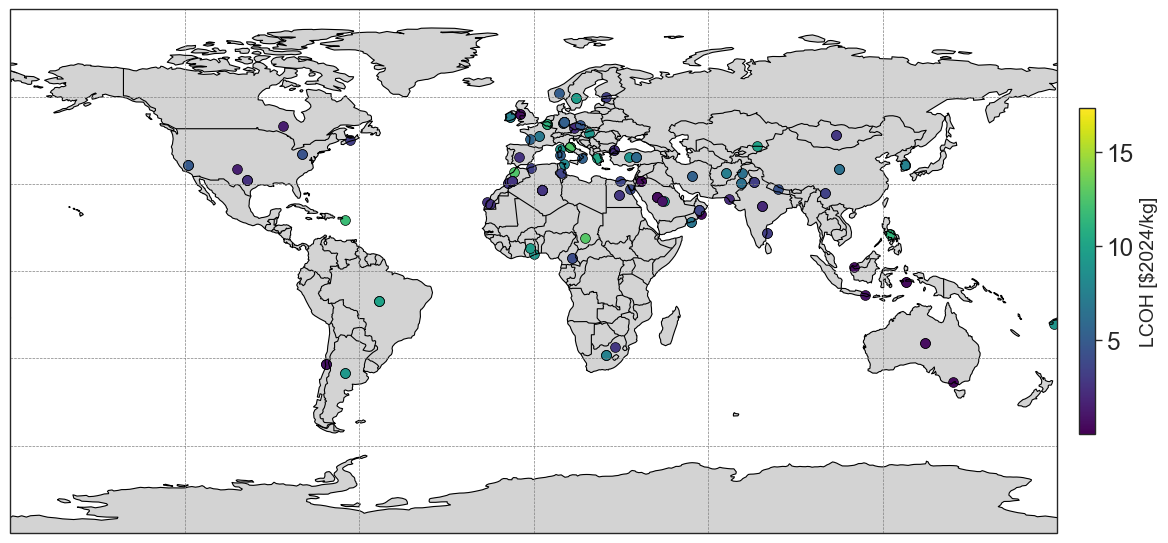

In [81]:
datasets = [
    {
    'df': cost_lcoh,
    'value_column': 'value_converted',
    #'entity_column': 'entity_mapping', 
    'title': ''
    }
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="LCOH [$2024/kg]",
    figsize=(14, 7),
    jitter_strength=0,
    default_point_size=50,
    #cmap="magma"
)

#fig.savefig("../data/figures/results/level_cost/pv_lcoe2024_worlmap.pdf", bbox_inches='tight')

#### **Lifetime**

In [ ]:
lifetime = pd.read_parquet("../data/visualisation_files/df_technologies_lifetime.parquet")
lifetime = lifetime[lifetime['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/YR'
)]
lifetime["unit_normalized"].value_counts()

#### Select Entities

In [ ]:
lifetime = visualisation.convert_spatial(lifetime)
print(lifetime["entity_base_mapping"].value_counts())
len(lifetime)

In [ ]:
lifetime_bat = lifetime[lifetime["entity_base_mapping"].isin(['battery'])]

In [ ]:
lifetime_pv = lifetime[lifetime["entity_base_mapping"].isin(['pv'])]

In [ ]:
datasets = [
    {
    'df': lifetime_bat,
    'value_column': 'value_normalized',
    #'entity_column': 'entity_base_mapping', 
    'title': 'a) Battery'
    },
    {
    'df': lifetime_pv,
    'value_column': 'value_normalized',
    #'entity_column': 'entity_base_mapping', 
    'title': 'b) PV'
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="Lifetime [Years]",
    figsize=(20, 10),
    jitter_strength=0,
    default_point_size=50,
    cmap="magma"
)
fig.savefig("../data/figures/results/lifetime/windturbine_lifetime_worldmap.pdf", bbox_inches='tight')

#### **Efficiency**

In [ ]:
efficiency = pd.read_parquet("../data/visualisation_files/df_technologies_efficiency.parquet")
efficiency = efficiency[efficiency['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/PERCENT'
)]
efficiency["unit_normalized"].value_counts()

#### Select Entities

In [ ]:
efficiency = efficiency[efficiency["entity_base_mapping"].isin(['pv', 'battery', 'wind turbine', 'electrolyzer'])]

In [ ]:
efficiency = visualisation.convert_spatial(efficiency)
print(efficiency["entity_base_mapping"].value_counts())
len(efficiency)

In [ ]:
datasets = [
    {
    'df': efficiency,
    'marker': 'o',
    'value_column': 'value_normalized',
    'color_column': 'entity_base_mapping', 
    'size_legend_title': 'Efficiency [%]', 
    'size_legend_position': (0.117,0.07),
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    'entity_base_mapping',
    title="Geographical Distribution of Technology Mentions in Scientific Literature",
    color_legend_position=(0.247,0.026),
    color_legend_title="Technology Type",
    figsize=(14, 8),
    jitter_strength=0,
    default_point_size=10
)
fig.savefig("../data/figures/results/efficiency/technologies_efficiency_worldmap.pdf", bbox_inches='tight')

#### **Capacity**

In [ ]:
capacity = pd.read_excel("../data/visualisation_files/unit_converted/df_technologies_capacity_mw.xlsx")

#### Select Entities

In [ ]:
#capacity = capacity[capacity["entity_base_mapping"].isin(['pv', 'battery', 'wind turbine', 'electrolyzer'])]

#capacity = capacity[capacity["entity_mapping"].isin(['PVSystem', 'Wind Turbine'])]

# capacity = capacity[capacity["entity_mapping"].isin(['Offshore Wind Turbine', 'Floating Offshore Wind Turbine', 'Onshore Wind Turbine'])]
# capacity["entity_mapping"] = capacity["entity_mapping"].replace({
#     'Offshore Wind Turbine': 'Offshore',
#     'Floating Offshore Wind Turbine': 'Floating Offshore',
#     'Onshore Wind Turbine': 'Onshore'
# })

capacity = capacity[capacity["entity_mapping"].isin(['Hybrid PV System', 'Utility-scale PV System', 'Rooftop PV System', 'Photovoltaic-Thermal System (PVT)'])]
capacity["entity_mapping"] = capacity["entity_mapping"].replace({
    'Hybrid PV System': 'Hybrid PV',
    'Utility-scale PV System': 'Utility-scale PV',
    'Rooftop PV System': 'Rooftop PV',
    'Photovoltaic-Thermal System (PVT)': 'PVT'
})

capacity = capacity[capacity["property"].isin(['installed capacity'])]

In [ ]:
capacity = visualisation.convert_spatial(capacity)
print(capacity["entity_mapping"].value_counts().iloc[:20])

In [ ]:
datasets = [
    {
    'df': capacity,
    'marker': 'o',
    'value_column': 'value_converted',
    'color_column': 'entity_mapping', 
    'size_legend_title': 'Installed Capacity [MW]', 
    'size_legend_position': (0.315,0.07),
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    'entity_mapping',
    title="Geographical Distribution of Technology Mentions in Scientific Literature",
    color_legend_position=(0.117,0.07),
    color_legend_title="PV Type",
    figsize=(14, 8),
    jitter_strength=0,
    default_point_size=15
)
fig.savefig("../data/figures/results/capacity/pv_capacity_worldmap.pdf", bbox_inches='tight')

#### Emission 

In [3]:
emission = pd.read_parquet("../data/visualisation_files/df_emission.parquet")
emission = emission[emission['unit_normalized'].apply(
    lambda lst: len(lst) == 1 and lst[0].get('unit_uri') == 'http://qudt.org/vocab/unit/KiloGM'
)]
emission["unit_normalized"].value_counts()

unit_normalized
[{'exponent': 1.0, 'text': 'kg', 'unit_uri': 'http://qudt.org/vocab/unit/KiloGM', 'year': None}]           1914
[{'exponent': -1.0, 'text': 'kg', 'unit_uri': 'http://qudt.org/vocab/unit/KiloGM', 'year': None}]             4
[{'exponent': 1.0, 'text': 'kilogram', 'unit_uri': 'http://qudt.org/vocab/unit/KiloGM', 'year': None}]        4
[{'exponent': 1.0, 'text': 'kilograms', 'unit_uri': 'http://qudt.org/vocab/unit/KiloGM', 'year': None}]       3
Name: count, dtype: int64

In [ ]:
emission["property"].value_counts().head(40)

In [ ]:
emission["unit_normalized"].value_counts().head(30)

#### Select Entities

In [4]:
emission = emission[emission["property_mapping"] == "CO2 emission"]

In [6]:
emission = visualisation.convert_spatial(emission)
print(emission["property_mapping"].value_counts())

property_mapping
CO2 emission    215
Name: count, dtype: int64


In [ ]:
emission = emission[(emission["value_normalized"] >= 0) & (emission["value_normalized"] <= 100)]

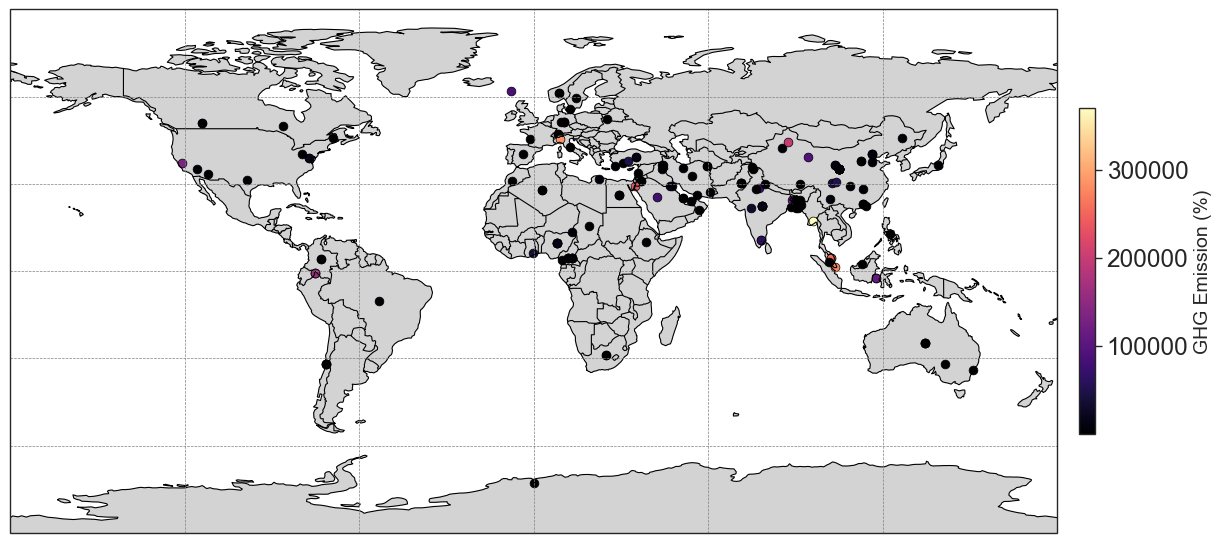

In [7]:
datasets = [
    {
    'df': emission,
    'value_column': 'value_normalized',
    #'entity_column': 'entity_mapping', 
    },
]

fig = visualisation.plot_multiple_datasets_on_world(
    datasets,
    colorbar_title="GHG Emission (%)",
    figsize=(14, 7),
    jitter_strength=0,
    default_point_size=40,
    cmap="magma"
)
#fig.savefig("../data/figures/results/capacity/ghg_emission_worldmap.pdf", bbox_inches='tight')